# Figure 5 — versione pulita con mappe di superficie

Riproduce la figura con pannelli (a), (b), (c1), (c2), (d), (e), (f) di Figure 5. Cambiano soltanto le mappe: quattro viste **LH lateral, LH medial, RH lateral, RH medial**, su una riga per pannello, sulle superfici inflated fsLR 32k di neuromaps.

File originali: `EC_matrix_HCP1_100.npy` per EC (prime 100 corticali); `community_div.npy` per la partizione già salvata; `nifti_S.nii` per i 100 SSI originali. Non viene rifatto il fit, lo SBM o il calcolo dello SSI, né usato il profilo recente a 144 soggetti. La provenienza/coorte del vecchio NIfTI non è ricostruita qui.

Si conservano il t-test a un campione, Bonferroni sui soli elementi fuori diagonale, la NMI e l'aggregazione dei pannelli d/e del codice originale. In d/e il denominatore include **tutte le coppie di parcelle del blocco**, anche quelle azzerate e le diagonali: è la convenzione originale, non una media condizionata ai soli archi significativi. L'orientamento delle matrici originali è mantenuto. Il file delle comunità viene usato così com'è, senza inferirne la soglia di generazione.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import colors, cm, font_manager
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests
from sklearn.metrics import normalized_mutual_info_score
from nilearn import plotting

PROJECT = Path('/home/benedetta/Scripts/Insight_project')
DATA = PROJECT / 'numpy files'
FIGURE_PATH = PROJECT / 'Figures/Figure_5_clean.jpg'
deps = PROJECT / '.deps/neuromaps'
if str(deps) not in sys.path: sys.path.insert(0, str(deps))
from neuromaps.datasets import fetch_fslr
font = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family'] = font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams.update({'font.size':20, 'axes.titlesize':24, 'axes.labelsize':20, 'xtick.labelsize':18, 'ytick.labelsize':18})

JS = np.load(DATA / 'EC_matrix_HCP1_100.npy', mmap_mode='r')[:, :100, :100]
communities = np.load(DATA / 'community_div.npy').squeeze()
assert communities.shape == (100,)
_, community_ids = np.unique(communities, return_inverse=True)
ncomm = len(np.unique(community_ids))
label_file = Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
full_labels = [line.split()[1] for line in label_file.read_text().splitlines() if line.strip()]
labels = [s.removeprefix('7Networks_') for s in full_labels]
yeo_names = ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']
network_names = [f'{h}_{n}' for h in ['LH','RH'] for n in yeo_names]
net_ids = np.array([network_names.index('_'.join(s.split('_')[:2])) for s in labels])
yeo_ids = net_ids % 7

# Recover the exact parcel values from the existing SSI volume.
ssi_img = nib.load(PROJECT / 'Notebook figure/nifti_S.nii')
atlas = nib.load('/home/allegra/atlases/Schaefer2018_100Parcels_7Networks_order_FSLMNI152_1mm.nii')
assert ssi_img.shape == atlas.shape
np.testing.assert_allclose(ssi_img.affine, atlas.affine)
atlas_data = np.asarray(atlas.dataobj).astype(int)
ssi_data = ssi_img.get_fdata()
source_sink_S = np.array([ssi_data[atlas_data == k][0] for k in range(1,101)])
for k in range(1,101):
    assert np.all(ssi_data[atlas_data == k] == source_sink_S[k-1])
assert np.isfinite(source_sink_S).all()
print(f'EC: {JS.shape}; communities: {ncomm}; SSI: 100 values from nifti_S.nii')


/home/benedetta/Scripts/Insight_project/.deps/neuromaps/neuromaps/datasets/utils.py:6: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


EC: (1013, 100, 100); communities: 19; SSI: 100 values from nifti_S.nii


## Calcoli originali dei pannelli a, b, d, e

In [2]:
mean_ec = np.mean(JS, axis=0)
offdiag = ~np.eye(100, dtype=bool)
_, pvalues = ttest_1samp(JS, popmean=0, axis=0)
sig_mask = np.zeros((100,100), dtype=bool)
sig_mask[offdiag] = multipletests(pvalues[offdiag], method='bonferroni', alpha=.05)[0]
vis_ec = np.full((100,100), np.nan)
vis_ec[sig_mask] = mean_ec[sig_mask]
mat = mean_ec.copy()
mat[~sig_mask] = 0
np.fill_diagonal(mat, 0)
pos_net = np.zeros((14,14)); neg_net = np.zeros((14,14))
for i in range(14):
    for j in range(14):
        block = mat[np.ix_(net_ids == i, net_ids == j)]
        pos_net[i,j] = np.where(block > 0, block, 0).mean()
        neg_net[i,j] = np.where(block < 0, block, 0).mean()
community_overlap = np.zeros((ncomm,7))
for c,n in zip(community_ids,yeo_ids): community_overlap[c,n] += 1
community_overlap /= community_overlap.sum(axis=1,keepdims=True)
nmi = normalized_mutual_info_score(community_ids,yeo_ids)
print(f'Significant off-diagonal fraction: {sig_mask.sum()/offdiag.sum():.4f}; NMI: {nmi:.6f}')


Significant off-diagonal fraction: 0.8073; NMI: 0.628840


## Mapping Schaefer-100 → superficie fsLR e funzioni di plot
Etichette CIFTI verificate contro quelle del volume; valori assegnati senza interpolazione ai vertici. Per le mappe categoriali, la mediana dei tre vertici di ogni faccia conserva una delle classi esistenti. Parete mediale esclusa. [Documentazione neuromaps](https://netneurolab.github.io/neuromaps/generated/neuromaps.datasets.fetch_fslr.html).

In [3]:
surfaces = fetch_fslr(density='32k', data_dir=Path.home()/'neuromaps-data', verbose=0)
cifti = nib.load(PROJECT / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii')
label_table = cifti.header.get_axis(0).label[0]
assert [label_table[k][0] for k in range(1,101)] == full_labels
surface_labels = np.asarray(cifti.dataobj)[0].astype(int)
assert np.array_equal(np.unique(surface_labels), np.arange(101))
hemisphere_labels = {}
for name, sl, bm in cifti.header.get_axis(1).iter_structures():
    h = 'left' if name == 'CIFTI_STRUCTURE_CORTEX_LEFT' else 'right'
    v = np.zeros(bm.nvertices[name], dtype=int)
    v[bm.vertex] = surface_labels[sl]
    hemisphere_labels[h] = v

def surface_row(fig, spec, values, title, cmap, vmin, vmax, ticks=None, ticklabels=None, categorical=False):
    grid = spec.subgridspec(1,5,width_ratios=[1,1,1,1,.04],wspace=.015)
    first = None
    for j,(h,view) in enumerate([('left','lateral'),('left','medial'),('right','lateral'),('right','medial')]):
        hi = 0 if h == 'left' else 1
        vertex_labels = hemisphere_labels[h]
        vertex_values = np.full(vertex_labels.shape,np.nan)
        valid = vertex_labels > 0
        vertex_values[valid] = values[vertex_labels[valid]-1]
        ax = fig.add_subplot(grid[0,j],projection='3d')
        plotting.plot_surf_stat_map(str(surfaces['inflated'][hi]),vertex_values,
            hemi=h,view=view,axes=ax,figure=fig,cmap=cmap,colorbar=False,
            symmetric_cbar=False,vmin=vmin,vmax=vmax,avg_method='median',alpha=1)
        ax.set_box_aspect(None, zoom=1.5)
        ax.set_title(f'{"LH" if hi==0 else "RH"} {view}',fontsize=20,pad=0)
        if first is None: first=ax
    first.text2D(0,1.23,title,transform=first.transAxes,fontsize=26,ha='left')
    cax = fig.add_subplot(grid[0,4])
    norm = colors.BoundaryNorm(np.arange(vmin,vmax+1,1),cmap.N) if categorical else colors.Normalize(vmin,vmax)
    cb = fig.colorbar(cm.ScalarMappable(norm=norm,cmap=cmap),cax=cax,ticks=ticks)
    if ticklabels is not None: cb.ax.set_yticklabels(ticklabels)
    cb.ax.tick_params(labelsize=18)
    return cb

def network_matrix(ax, matrix, cmap, vmin, vmax, title, fine=False):
    im=ax.imshow(matrix,cmap=cmap,vmin=vmin,vmax=vmax,interpolation='nearest')
    if fine:
        sizes=np.bincount(net_ids,minlength=14)
        edges=np.r_[0,np.cumsum(sizes)]
        centers=(edges[:-1]+edges[1:]-1)/2
        for e in edges[1:-1]:
            ax.axhline(e-.5,color='black',lw=.3); ax.axvline(e-.5,color='black',lw=.3)
    else: centers=np.arange(14)
    short=[s.replace('LH_','L-').replace('RH_','R-') for s in network_names]

    if fine:
        # Keep true block centres; spread labels with leader lines for legibility.
        ax.set_xticks([]); ax.set_yticks([])
        label_positions=np.linspace(2,97,14)
        for center,label_pos,label in zip(centers,label_positions,short):
            ax.annotate(label,xy=(center,99.5),xytext=(label_pos,107),
                xycoords='data',textcoords='data',rotation=90,ha='center',va='top',fontsize=20,
                annotation_clip=False,arrowprops={'arrowstyle':'-','lw':.5,'color':'.5'})
            ax.annotate(label,xy=(-.5,center),xytext=(-8,label_pos),
                xycoords='data',textcoords='data',ha='right',va='center',fontsize=20,
                annotation_clip=False,arrowprops={'arrowstyle':'-','lw':.5,'color':'.5'})
    else:
        ax.set_xticks(centers,short,rotation=90,fontsize=20)
        ax.set_yticks(centers,short,fontsize=20)
    ax.set_title(title,pad=7)
    return im


pixdim[1,2,3] should be non-zero; setting 0 dims to 1


## Figura completa e salvataggio
La cella salva un solo JPG. Scala SSI originale: −2…2. Stessi colori delle categorie e stessi limiti robusti al 95° percentile per d/e.

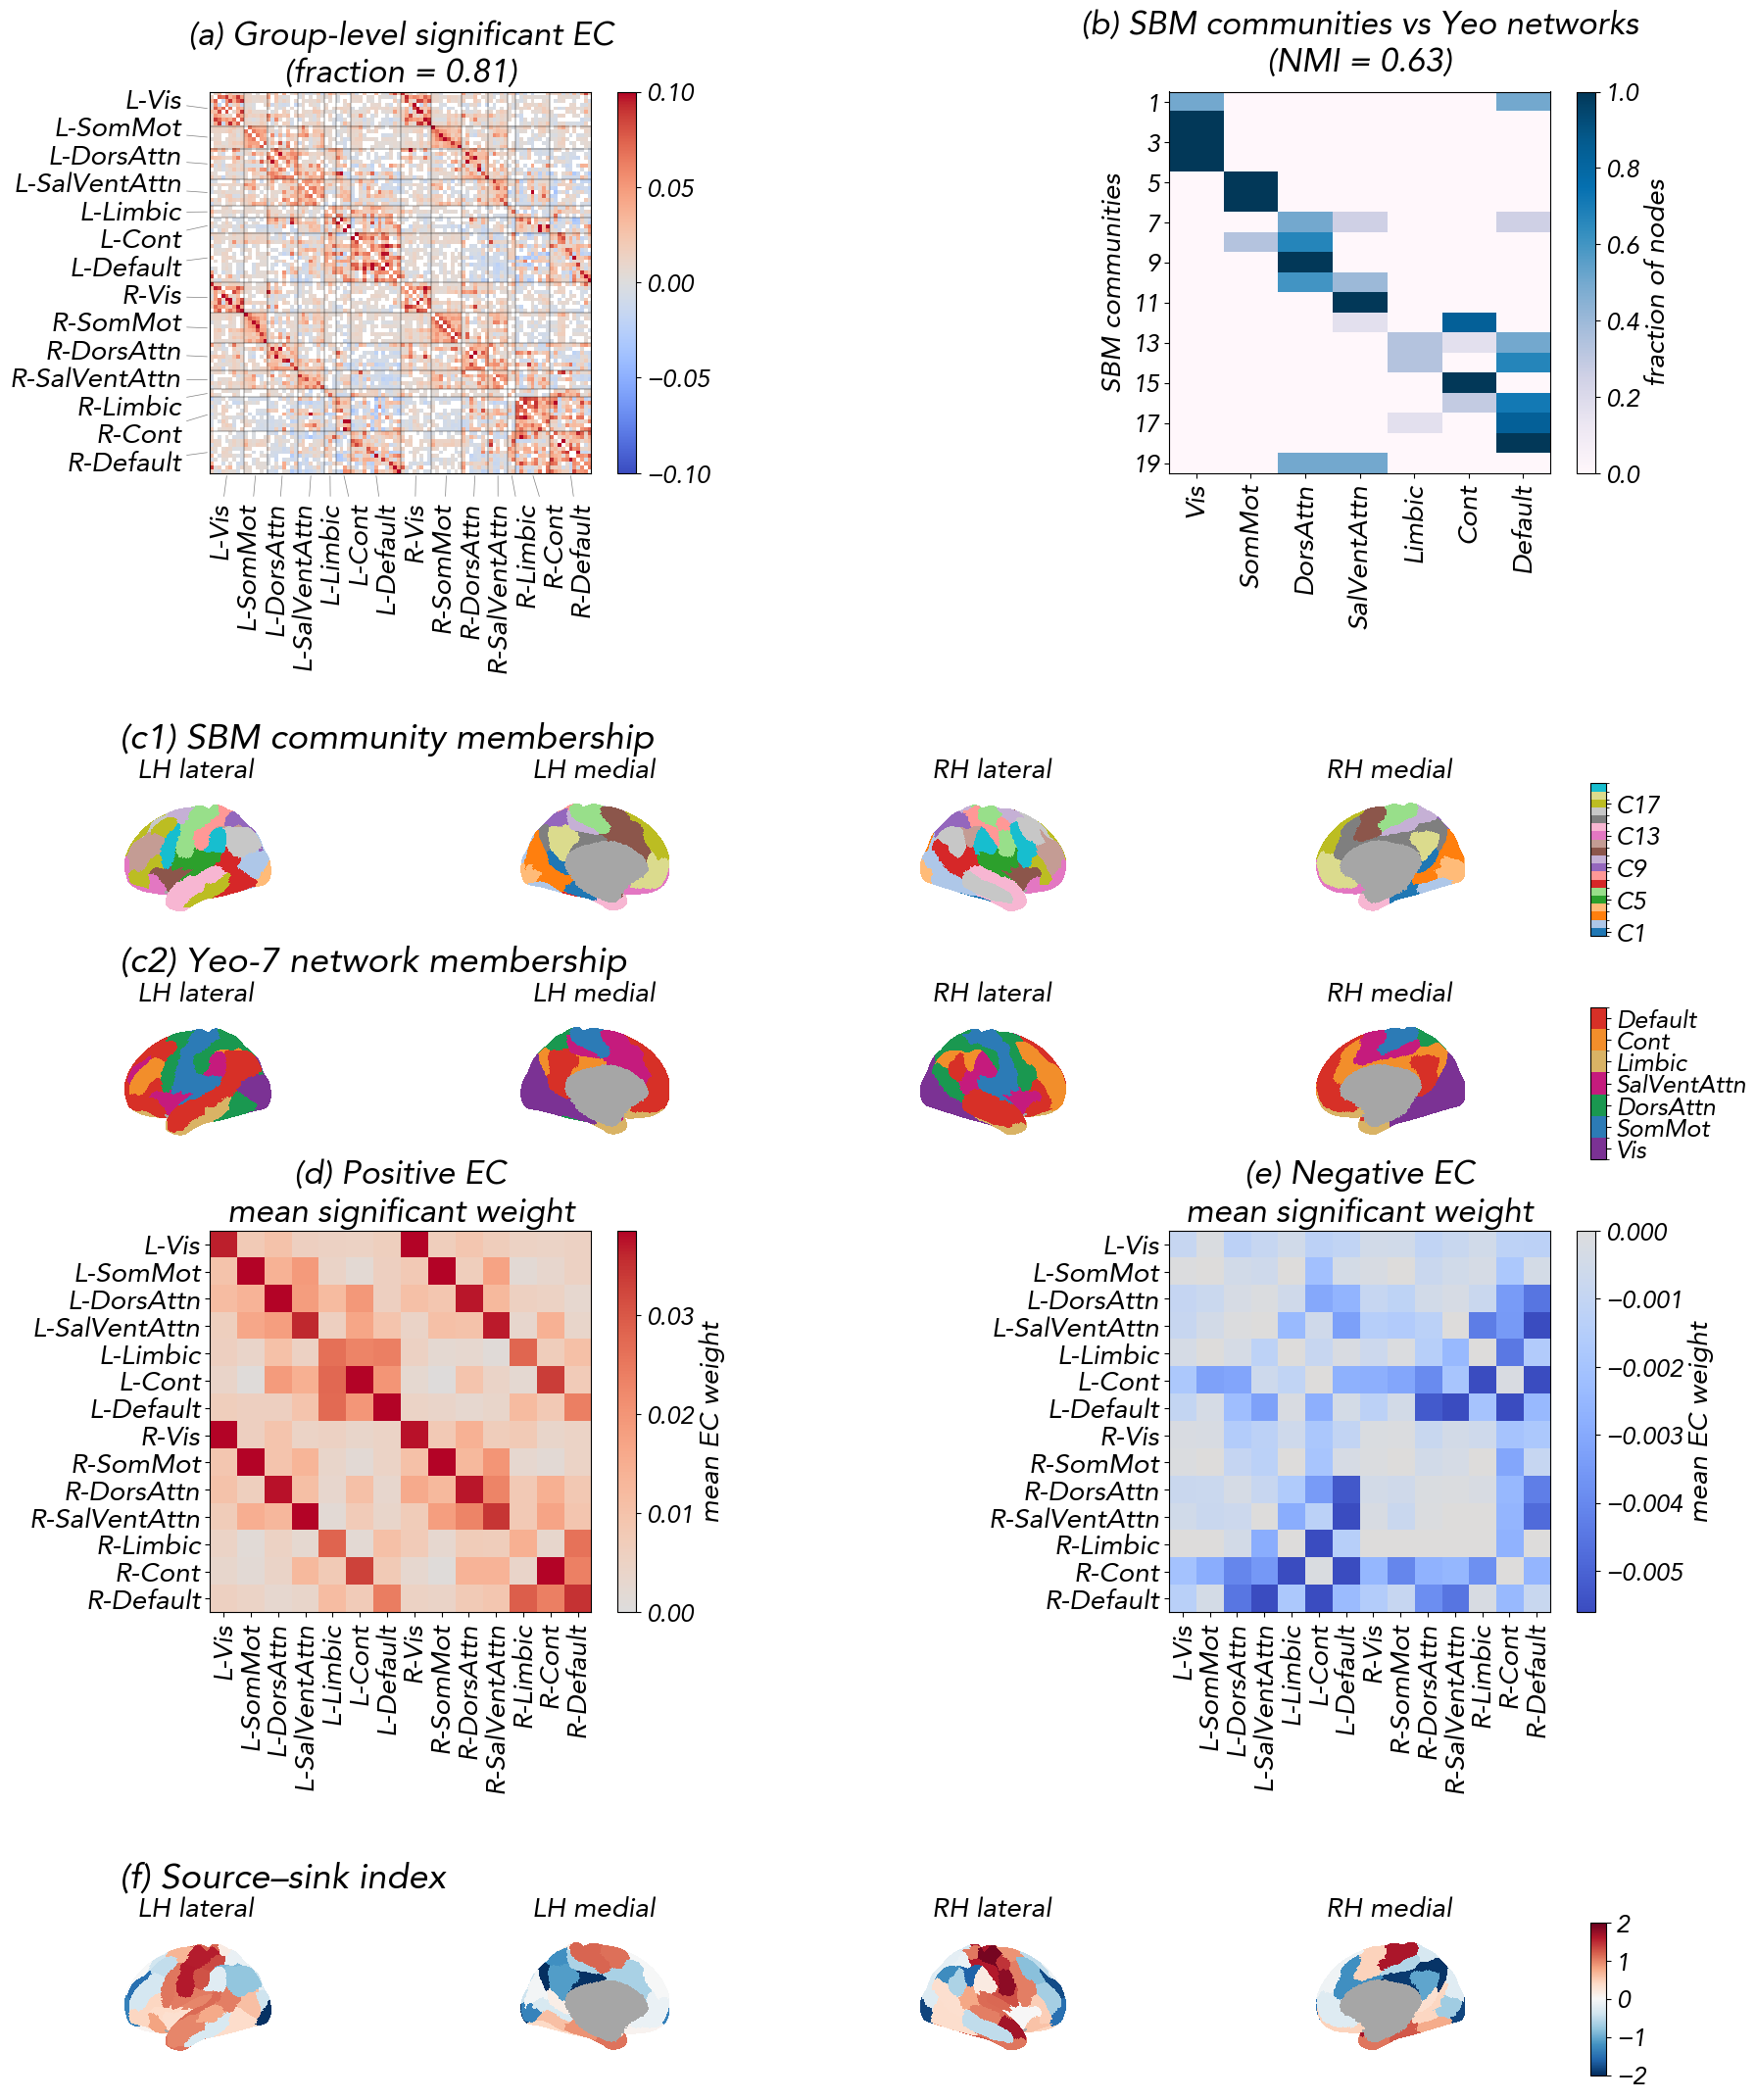

Saved: /home/benedetta/Scripts/Insight_project/Figures/Figure_5_clean.jpg


In [4]:
fig=plt.figure(figsize=(20,22),facecolor='white')
gs=fig.add_gridspec(7,2,height_ratios=[5,2.2,2,2,5,2.2,2],left=.09,right=.91,top=.96,bottom=.04,hspace=.32,wspace=.48)
ax_a=fig.add_subplot(gs[0,0]); ax_b=fig.add_subplot(gs[0,1])
ax_d=fig.add_subplot(gs[4,0]); ax_e=fig.add_subplot(gs[4,1])
cmap_ec=plt.get_cmap('coolwarm').copy(); cmap_ec.set_bad('white')
im=network_matrix(ax_a,vis_ec,cmap_ec,-.1,.1,
    f'(a) Group-level significant EC\n(fraction = {sig_mask.sum()/offdiag.sum():.2f})',fine=True)
fig.colorbar(im,ax=ax_a,fraction=.046,pad=.04)
im=ax_b.imshow(community_overlap,cmap='PuBu',aspect='auto')
ax_b.set_box_aspect(1)
ax_b.set_xticks(np.arange(7),yeo_names,rotation=90,fontsize=20)
ax_b.set_yticks(np.arange(0,ncomm,2),np.arange(1,ncomm+1,2))
ax_b.set_ylabel('SBM communities')
ax_b.set_title(f'(b) SBM communities vs Yeo networks\n(NMI = {nmi:.2f})',pad=15)
fig.colorbar(im,ax=ax_b,fraction=.046,pad=.04,label='fraction of nodes')

comm_colors=plt.cm.tab20(np.linspace(0,1,20))[:ncomm] if ncomm<=20 else plt.cm.nipy_spectral(np.linspace(.05,.95,ncomm))
cmap_comm=colors.ListedColormap(comm_colors)
surface_row(fig,gs[2,:],community_ids+1,'(c1) SBM community membership',cmap_comm,.5,ncomm+.5,
    ticks=np.arange(1,ncomm+1,4),ticklabels=[f'C{k}' for k in range(1,ncomm+1,4)],categorical=True)
cmap_yeo=colors.ListedColormap(['#7B3294','#2C7BB6','#1A9850','#C51B7D','#D9B365','#F28E2B','#D73027'])
surface_row(fig,gs[3,:],yeo_ids+1,'(c2) Yeo-7 network membership',cmap_yeo,.5,7.5,
    ticks=np.arange(1,8),ticklabels=yeo_names,categorical=True)

base=plt.get_cmap('coolwarm')
reds=colors.ListedColormap(base(np.linspace(.5,1,256)))
blues=colors.ListedColormap(base(np.linspace(0,.5,256)))
pos_vmax=np.percentile(pos_net,95); neg_vmax=np.percentile(np.abs(neg_net),95)
if pos_vmax==0: pos_vmax=pos_net.max()
if neg_vmax==0: neg_vmax=np.abs(neg_net).max()
im=network_matrix(ax_d,pos_net,reds,0,pos_vmax,'(d) Positive EC\nmean significant weight')
fig.colorbar(im,ax=ax_d,fraction=.046,pad=.04,label='mean EC weight')
im=network_matrix(ax_e,neg_net,blues,-neg_vmax,0,'(e) Negative EC\nmean significant weight')
fig.colorbar(im,ax=ax_e,fraction=.046,pad=.04,label='mean EC weight')
surface_row(fig,gs[6,:],source_sink_S,'(f) Source–sink index',plt.get_cmap('RdBu_r'),-2,2,ticks=[-2,-1,0,1,2])
FIGURE_PATH.parent.mkdir(parents=True,exist_ok=True)
fig.savefig(FIGURE_PATH,dpi=300,bbox_inches='tight',facecolor='white')
plt.show()
print('Saved:',FIGURE_PATH)
